# MLP Training Using Backpropagation for CIFAR10 dataset
<i> Wardatul Keskin | 301294696

In [106]:
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint 

## Data Loading and Exploration

In [107]:
# LOAD CIFAR dataset
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

In [108]:
# Dataset overview
print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)
print("Label shape (train):", y_train.shape)
print("Label shape (test):", y_test.shape)
print("Pixel value range:", X_train.min(), "to", X_train.max())

# Basic pixel statistics
print("\nPixel statistics (Train set):")
print(f"Mean: {np.mean(X_train):.2f}")
print(f"Standard Deviation: {np.std(X_train):.2f}")

Training data shape: (50000, 32, 32, 3)
Test data shape: (10000, 32, 32, 3)
Label shape (train): (50000, 1)
Label shape (test): (10000, 1)
Pixel value range: 0 to 255

Pixel statistics (Train set):
Mean: 120.71
Standard Deviation: 64.15


In [109]:
# Define class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Show class distribution in training data
unique, counts = np.unique(y_train, return_counts=True)
print("\nClass distribution in training data:")
for i in range(len(class_names)):
    print(f"{class_names[i]:10s} : {counts[i]} samples")


Class distribution in training data:
airplane   : 5000 samples
automobile : 5000 samples
bird       : 5000 samples
cat        : 5000 samples
deer       : 5000 samples
dog        : 5000 samples
frog       : 5000 samples
horse      : 5000 samples
ship       : 5000 samples
truck      : 5000 samples


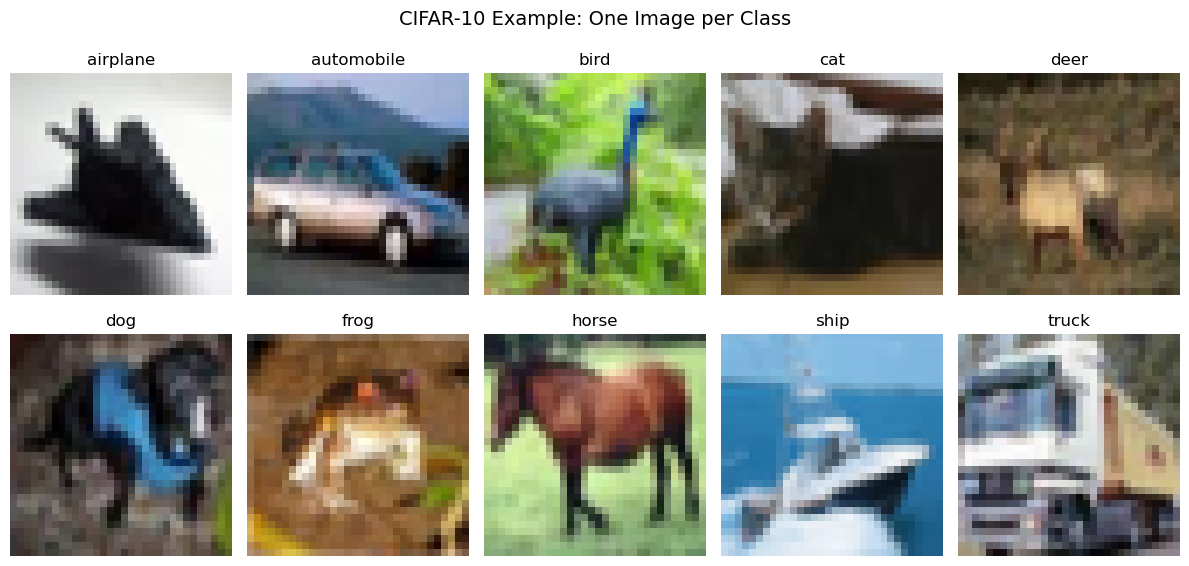

In [110]:
# Display one example per class
plt.figure(figsize=(12, 6))
for i in range(10):
    # Find the first occurrence of class i
    idx = np.where(y_train == i)[0][0]
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[idx])
    plt.title(class_names[i])
    plt.axis('off')
plt.suptitle("CIFAR-10 Example: One Image per Class", fontsize=14)
plt.tight_layout()
plt.show()

## Preprocess Data

In [111]:
# Normalize pixel values
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [112]:
# One-Hot Encode class labels (10 classes)
y_train = to_categorical(y_train, 10)
y_test  = to_categorical(y_test, 10)
print("After preprocessing:","\nX_train:", X_train.shape)
print("y_train:", y_train.shape)
print("Sample pixel range:", np.min(X_train), "→", np.max(X_train))

After preprocessing: 
X_train: (50000, 32, 32, 3)
y_train: (50000, 10)
Sample pixel range: 0.0 → 1.0


## Model

In [113]:
# Build MLP model
model = Sequential()
model.add(Flatten(input_shape=(32, 32, 3)))                             # Flatten images to 1-D vector
model.add(Dense(256, activation='relu', name="Hidden_layer1"))       # Hidden Layer 1
model.add(Dense(128, activation='relu', name="Hidden_layer2"))          # Hidden Layer 2
model.add(Dense(64, activation='relu', name="Hidden_Layer_3"))          # Hidden Layer 3
model.add(Dense(10, activation='softmax', name="Output"))               # Output Layer (10 classes)


Model: "sequential_102"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_102 (Flatten)       (None, 3072)              0         
                                                                 
 Hidden_layer1 (Dense)       (None, 256)               786688    
                                                                 
 Hidden_layer2 (Dense)       (None, 128)               32896     
                                                                 
 Hidden_Layer_3 (Dense)      (None, 64)                8256      
                                                                 
 Output (Dense)              (None, 10)                650       
                                                                 
Total params: 828490 (3.16 MB)
Trainable params: 828490 (3.16 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [114]:
# Compile the model
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [115]:
# Define callbacks
es = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)
mc = ModelCheckpoint('best_cifar10_mlp.h5', monitor='val_accuracy',
                     save_best_only=True, verbose=1)

## Training and Evaluation

In [116]:
# Train model
history = model.fit(X_train, y_train,
                    epochs=200,
                    batch_size=100,
                    validation_split=0.2,
                    callbacks=[es, mc],
                    verbose=1)

Epoch 1/200
398/400 [============================>.] - ETA: 0s - loss: 1.9104 - accuracy: 0.3074
Epoch 1: val_accuracy improved from -inf to 0.35130, saving model to best_cifar10_mlp.h5
400/400 [==============================] - 10s 21ms/step - loss: 1.9100 - accuracy: 0.3076 - val_loss: 1.7933 - val_accuracy: 0.3513
Epoch 2/200
400/400 [==============================] - ETA: 0s - loss: 1.7136 - accuracy: 0.3867
Epoch 2: val_accuracy improved from 0.35130 to 0.38820, saving model to best_cifar10_mlp.h5
400/400 [==============================] - 8s 21ms/step - loss: 1.7136 - accuracy: 0.3867 - val_loss: 1.7076 - val_accuracy: 0.3882
Epoch 3/200
398/400 [============================>.] - ETA: 0s - loss: 1.6338 - accuracy: 0.4147
Epoch 3: val_accuracy improved from 0.38820 to 0.41340, saving model to best_cifar10_mlp.h5
400/400 [==============================] - 8s 20ms/step - loss: 1.6338 - accuracy: 0.4148 - val_loss: 1.6416 - val_accuracy: 0.4134
Epoch 4/200
399/400 [==================

In [117]:
# Evaluate on test data
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


Test Accuracy: 50.35%
Test Loss: 1.5300


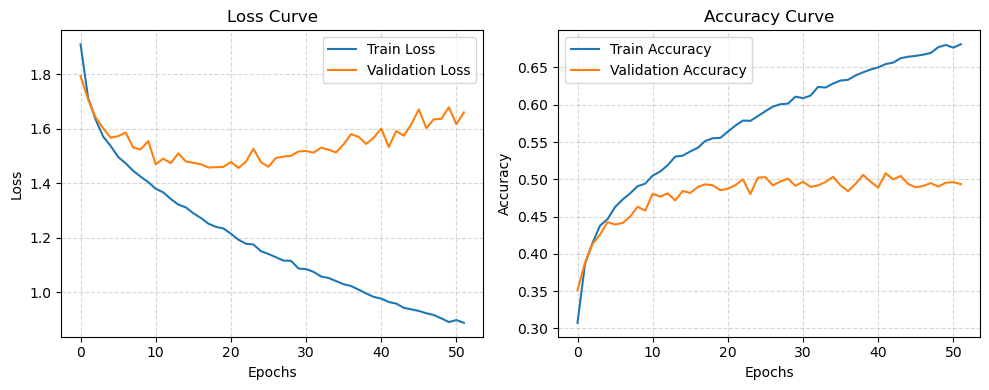

In [118]:
# Plot learning curves
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

313/313 [==============================] - 2s 5ms/step

=== Predicted vs Actual (first 10 samples) ===
Sample  1 → Predicted: deer       | Actual: cat
Sample  2 → Predicted: ship       | Actual: ship
Sample  3 → Predicted: ship       | Actual: ship
Sample  4 → Predicted: ship       | Actual: airplane
Sample  5 → Predicted: deer       | Actual: frog
Sample  6 → Predicted: frog       | Actual: frog
Sample  7 → Predicted: automobile | Actual: automobile
Sample  8 → Predicted: frog       | Actual: frog
Sample  9 → Predicted: bird       | Actual: cat
Sample 10 → Predicted: automobile | Actual: automobile


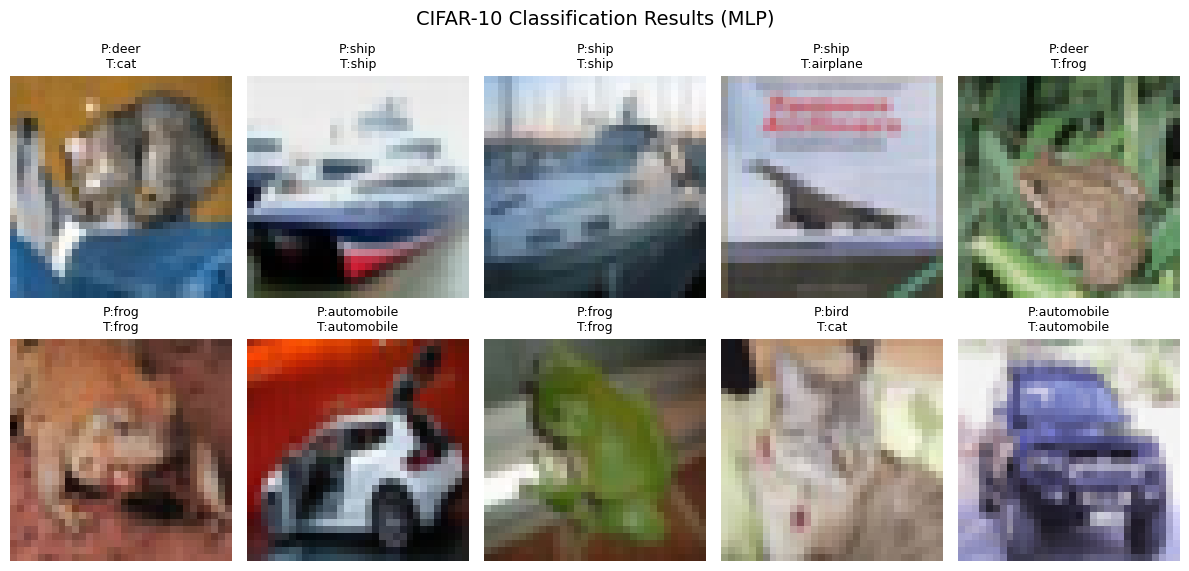

In [119]:
# Classification Output
predictions = model.predict(X_test)
pred_classes = np.argmax(predictions, axis=1)
true_classes = np.argmax(y_test, axis=1)

print("\n=== Predicted vs Actual (first 10 samples) ===")
for i in range(10):
    print(f"Sample {i+1:2d} → Predicted: {class_names[pred_classes[i]]:<10} | Actual: {class_names[true_classes[i]]}")

plt.figure(figsize=(12,6))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_test[i])
    plt.title(f"P:{class_names[pred_classes[i]]}\nT:{class_names[true_classes[i]]}", fontsize=9)
    plt.axis('off')
plt.suptitle("CIFAR-10 Classification Results (MLP)", fontsize=14)
plt.tight_layout()
plt.show()

## Experimenting with difference Network Architecture, activation functions, learning rates, batch sizes, and learning algorithms

In [120]:
results = []

# Define architectures (depth variation)
architectures = [
    (256, 128),            # 2 hidden layers
    (256, 128, 64),        # 3 hidden layers
]

# Activation functions
activations = ['relu', 'tanh', 'sigmoid']

# Learning rates
learning_rates = [0.001, 0.01]

# Batch sizes
batch_sizes = [64, 128]

# Optimizers(learning algorithms)
optimizers = ['adam', 'rmsprop', 'sgd']

# Run experiments
for opt in optimizers:
    for act in activations:
        for lr in learning_rates:
            for bs in batch_sizes:
                for arch in architectures:
                    print(f"\n=== Training Optimizer={opt}, Activation={act}, LR={lr}, Batch={bs}, Arch={arch} ===")
                    model = build_mlp(hidden_layers=arch,
                                      activation=act,
                                      optimizer=opt,
                                      lr=lr)

                    # Early stopping & checkpoint
                    es = EarlyStopping(monitor='val_accuracy', patience=15, restore_best_weights=True)
                    mc = ModelCheckpoint('best_cifar10_full_exp.h5',
                                         monitor='val_accuracy', save_best_only=True, verbose=0)

                    # Train model
                    history = model.fit(X_train, y_train,
                                        epochs=20,
                                        batch_size=bs,
                                        validation_split=0.2,
                                        callbacks=[es, mc],
                                        verbose=1)

                    # Evaluate model
                    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
                    print(f"Test Accuracy: {test_acc*100:.2f}% | Test Loss: {test_loss:.4f}")

                    # Store results
                    results.append({
                        "optimizer": opt,
                        "architecture": arch,
                        "num_layers": len(arch),
                        "activation": act,
                        "learning_rate": lr,
                        "batch_size": bs,
                        "test_acc": test_acc,
                        "test_loss": test_loss,
                        "history": history
                    })


=== Training Optimizer=adam, Activation=relu, LR=0.001, Batch=64, Arch=(256, 128) ===
Epoch 1/20
625/625 [==============================] - 14s 20ms/step - loss: 1.9035 - accuracy: 0.3117 - val_loss: 1.7737 - val_accuracy: 0.3617
Epoch 2/20
625/625 [==============================] - 11s 18ms/step - loss: 1.7084 - accuracy: 0.3892 - val_loss: 1.7169 - val_accuracy: 0.3890
Epoch 3/20
625/625 [==============================] - 12s 19ms/step - loss: 1.6201 - accuracy: 0.4241 - val_loss: 1.6393 - val_accuracy: 0.4182
Epoch 4/20
625/625 [==============================] - 11s 17ms/step - loss: 1.5636 - accuracy: 0.4406 - val_loss: 1.6169 - val_accuracy: 0.4162
Epoch 5/20
625/625 [==============================] - 11s 18ms/step - loss: 1.5184 - accuracy: 0.4568 - val_loss: 1.5323 - val_accuracy: 0.4553
Epoch 6/20
625/625 [==============================] - 11s 18ms/step - loss: 1.4915 - accuracy: 0.4666 - val_loss: 1.5286 - val_accuracy: 0.4568
Epoch 7/20
625/625 [=============================

In [121]:
# Summary
sorted_results = sorted(results, key=lambda r: r["test_acc"], reverse=True)
print("\n=== Summary (Top 10 Configurations by Test Accuracy) ===")
for r in sorted_results[:10]:
    print(f"Acc={r['test_acc']*100:5.2f}% | Opt={r['optimizer']:<7s} | Layers={r['num_layers']:2d} "
          f"| Act={r['activation']:<8s} | LR={r['learning_rate']:<7} | Batch={r['batch_size']:<4} "
          f"| Arch={r['architecture']}")


=== Summary (Top 10 Configurations by Test Accuracy) ===
Acc=52.58% | Opt=sgd     | Layers= 2 | Act=tanh     | LR=0.01    | Batch=128  | Arch=(256, 128)
Acc=51.47% | Opt=sgd     | Layers= 3 | Act=tanh     | LR=0.01    | Batch=128  | Arch=(256, 128, 64)
Acc=51.26% | Opt=sgd     | Layers= 3 | Act=relu     | LR=0.01    | Batch=128  | Arch=(256, 128, 64)
Acc=50.92% | Opt=sgd     | Layers= 3 | Act=tanh     | LR=0.001   | Batch=64   | Arch=(256, 128, 64)
Acc=50.61% | Opt=sgd     | Layers= 3 | Act=relu     | LR=0.01    | Batch=64   | Arch=(256, 128, 64)
Acc=50.53% | Opt=sgd     | Layers= 2 | Act=tanh     | LR=0.01    | Batch=64   | Arch=(256, 128)
Acc=50.46% | Opt=sgd     | Layers= 2 | Act=relu     | LR=0.001   | Batch=64   | Arch=(256, 128)
Acc=50.42% | Opt=sgd     | Layers= 2 | Act=relu     | LR=0.01    | Batch=128  | Arch=(256, 128)
Acc=50.16% | Opt=sgd     | Layers= 3 | Act=relu     | LR=0.001   | Batch=64   | Arch=(256, 128, 64)
Acc=49.96% | Opt=sgd     | Layers= 3 | Act=tanh     | LR=0

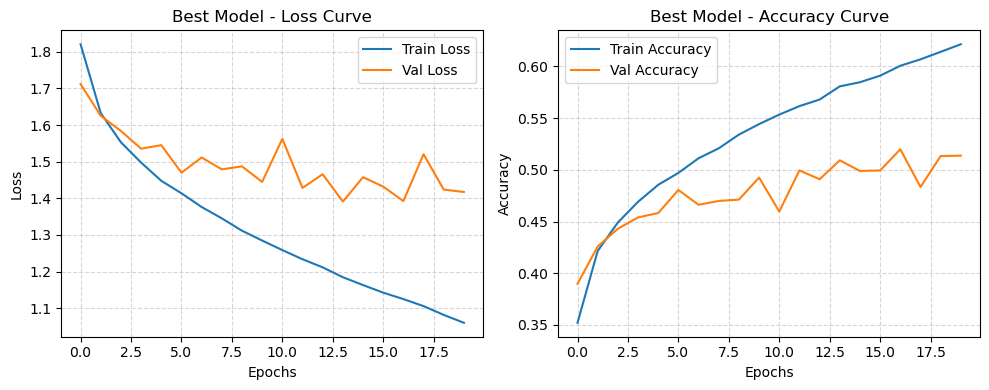

In [122]:
# Best Learning Curve
best = sorted_results[0]
history = best["history"].history

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history['loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Val Loss')
plt.title('Best Model - Loss Curve')
plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1,2,2)
plt.plot(history['accuracy'], label='Train Accuracy')
plt.plot(history['val_accuracy'], label='Val Accuracy')
plt.title('Best Model - Accuracy Curve')
plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


=== Predicted vs Actual (first 10 samples) ===
Sample  1 → Predicted: cat        | Actual: cat
Sample  2 → Predicted: truck      | Actual: ship
Sample  3 → Predicted: truck      | Actual: ship
Sample  4 → Predicted: airplane   | Actual: airplane
Sample  5 → Predicted: deer       | Actual: frog
Sample  6 → Predicted: frog       | Actual: frog
Sample  7 → Predicted: cat        | Actual: automobile
Sample  8 → Predicted: frog       | Actual: frog
Sample  9 → Predicted: deer       | Actual: cat
Sample 10 → Predicted: automobile | Actual: automobile


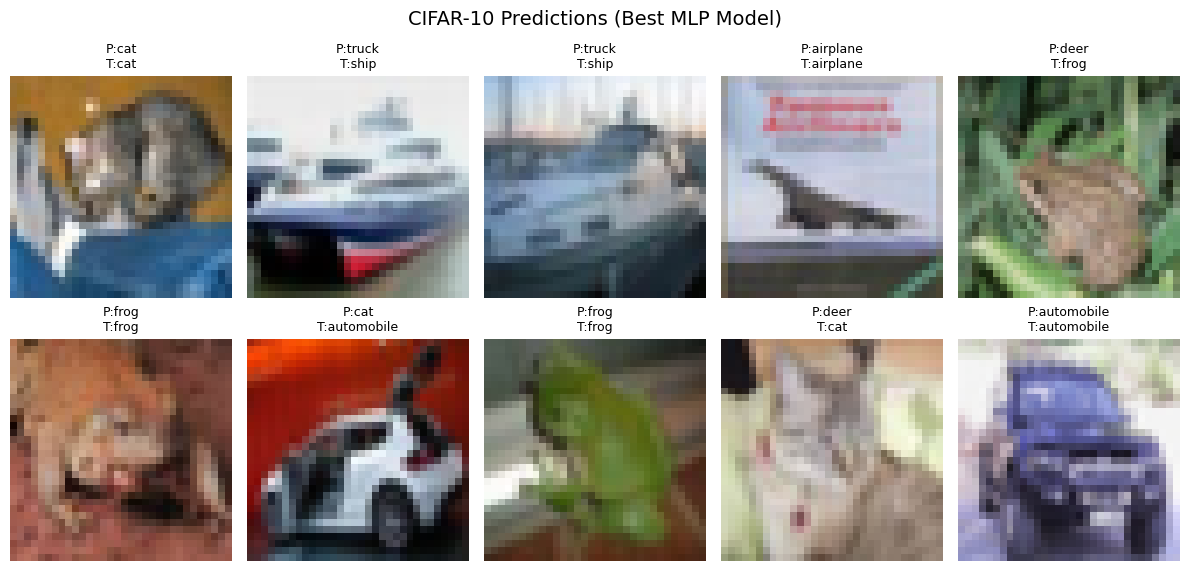

In [123]:
# Predicted and Actual Output
preds = best["history"].model.predict(X_test, verbose=0)
pred_classes = np.argmax(preds, axis=1)
true_classes = np.argmax(y_test, axis=1)

print("\n=== Predicted vs Actual (first 10 samples) ===")
for i in range(10):
    print(f"Sample {i+1:2d} → Predicted: {class_names[pred_classes[i]]:<10} | Actual: {class_names[true_classes[i]]}")

plt.figure(figsize=(12,6))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_test[i])
    plt.title(f"P:{class_names[pred_classes[i]]}\nT:{class_names[true_classes[i]]}", fontsize=9)
    plt.axis('off')
plt.suptitle("CIFAR-10 Predictions (Best MLP Model)", fontsize=14)
plt.tight_layout()
plt.show()